add yolo26.pt and scratch_lpr_cnn.pt to the content folder


In [2]:
%pip install -q ultralytics
%pip install -q matplotlib opencv-python pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 6.6 MB/s eta 0:00:00


In [3]:
import os
import shutil
import time
import random
from tqdm import tqdm

import gdown
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data

from torchvision import models
from torchvision import transforms

from ultralytics import YOLO
import torch
import torch.nn as nn
from torchvision import transforms
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [5]:
yolo_path='/content/yolo26.pt'
cnn_path='/content/scratch_lpr_cnn.pt'

In [6]:
class ResidualConvBlock(nn.Module):
    def __init__(self, channels: int, dropout: float = 0.1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True),
            nn.Dropout2d(p=dropout),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
        )
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(x + self.block(x))

class ScratchPlateCNN(nn.Module):
    def __init__(self, num_letter_classes: int, plate_len: int = 8):
        super().__init__()
        self.plate_len = plate_len
        self.letter_position = 2

        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.stage1 = ResidualConvBlock(64, dropout=0.1)
        self.pool1 = nn.MaxPool2d(2)
        self.stage2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            ResidualConvBlock(128, dropout=0.15),
        )
        self.pool2 = nn.AdaptiveAvgPool2d((1, 1))
        self.feature_norm = nn.LayerNorm(128)
        self.dropout = nn.Dropout(p=0.35)
        self.digit_heads = nn.ModuleList(
            [nn.Linear(128, 10) for _ in range(plate_len) if _ != self.letter_position]
        )
        self.letter_head = nn.Linear(128, num_letter_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.stage1(x))
        x = self.stage2(x)
        x = self.pool2(x).flatten(1)
        x = self.feature_norm(x)
        x = self.dropout(x)

        outputs = []
        digit_idx = 0
        for pos in range(self.plate_len):
            if pos == self.letter_position:
                outputs.append(self.letter_head(x))
            else:
                outputs.append(self.digit_heads[digit_idx](x))
                digit_idx += 1
        return outputs



In [7]:
# 2. Load the bundled dictionary from the .pt file
checkpoint = torch.load(cnn_path, map_location=torch.device('cpu'))

# 3. Extract the configuration and initialize the blank model
config = checkpoint["config"]
lpr_model = ScratchPlateCNN(num_letter_classes=config["num_letter_classes"])

# 4. Inject the trained weights into the blank model
lpr_model.load_state_dict(checkpoint["model_state_dict"])

# 5. Lock the model into evaluation mode (critical for inference)
lpr_model.eval()

print("Phase 2 Custom CNN successfully loaded and ready for inference!")


Phase 2 Custom CNN successfully loaded and ready for inference!


In [8]:
# ==========================================
# 2. SETUP PIPELINE MODELS
# ==========================================

# Phase 1: Load YOLO Detector
yolo_model = YOLO(yolo_path)

# Phase 2: Load CNN Recognizer
checkpoint = torch.load(cnn_path, map_location=device)
config = checkpoint["config"]
idx_to_letter = {i: ch for i, ch in enumerate(config["letter_alphabet"])}
ascii_digits = config["ascii_digits"]

cnn_model = ScratchPlateCNN(num_letter_classes=config["num_letter_classes"]).to(device)
cnn_model.load_state_dict(checkpoint["model_state_dict"])
cnn_model.eval()

# Preprocessing pipeline identical to training loop
lpr_transform = transforms.Compose([
    transforms.Resize((64, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=config["normalize_mean"], std=config["normalize_std"]),
])

In [9]:
def process_license_plate(image_path):
    # 1. Read Image
    original_img = cv2.imread(image_path)
    if original_img is None:
        print("Image could not be found or loaded.")
        return

    # Convert BGR to RGB for matplotlib and PIL
    img_rgb = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)

    # 2. YOLO Detection
    results = yolo_model(img_rgb, verbose=False)[0]

    if len(results.boxes) == 0:
        print("No license plate detected in this image.")
        plt.imshow(img_rgb)
        plt.title("No Plate Detected")
        plt.axis('off')
        plt.show()
        return

    # Isolate the box with the highest confidence
    best_box_idx = results.boxes.conf.argmax()
    x1, y1, x2, y2 = results.boxes.xyxy[best_box_idx].cpu().numpy().astype(int)

    # 3. Crop and Format Plate
    plate_crop_np = img_rgb[y1:y2, x1:x2]
    plate_pil = Image.fromarray(plate_crop_np)

    # Transform crop to match PyTorch expectations [1, 3, 64, 256]
    input_tensor = lpr_transform(plate_pil).unsqueeze(0).to(device)

    # 4. PyTorch Recognition
    with torch.no_grad():
        logits_list = cnn_model(input_tensor)

    # Map raw logits back to characters
    preds = [logits.argmax(dim=1).item() for logits in logits_list]

    plate_chars = []
    for pos, idx in enumerate(preds):
        if pos == config["letter_position"]:
            plate_chars.append(idx_to_letter[idx])
        else:
            plate_chars.append(ascii_digits[idx])

    final_plate_text = "".join(plate_chars)

    # 5. Visualization Output
    plt.figure(figsize=(10, 8))

    # Draw the green bounding box on the original image
    cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 4)

    plt.imshow(img_rgb)
    plt.title(f"Recognized Plate: {final_plate_text}", fontsize=20, fontweight='bold', color='darkgreen')
    plt.axis('off')
    plt.show()

Enter the image file name (including .jpg): test.jpeg


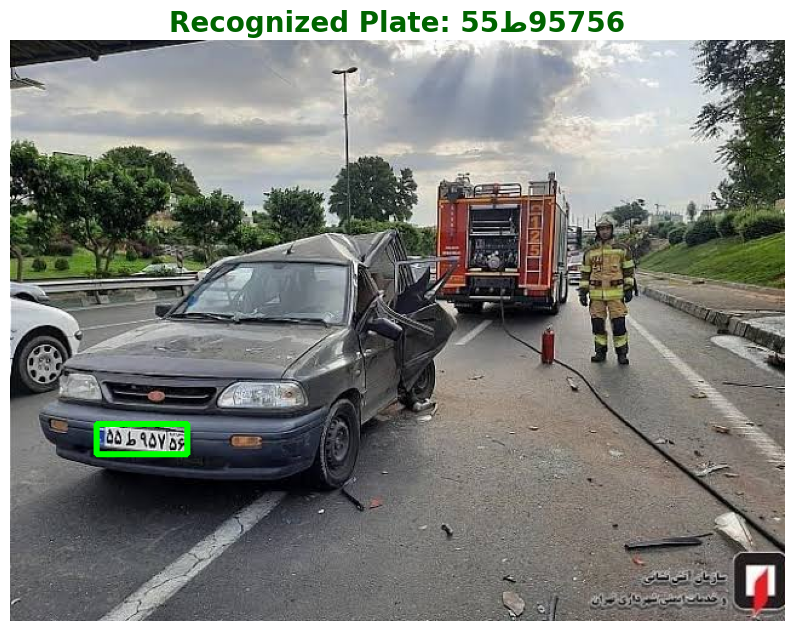

In [15]:
filename = input("Enter the image file name (including .jpg): ")

image_path = f"/content/{filename}"

process_license_plate(image_path)

